# 01:Exploratory Data Analysis (EDA)

In [ ]:
import sys
sys.path.append('..')   

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import config as cfg
from src.preprocess import load_raw, clean, encode

plt.rcParams['figure.dpi']      = 120
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

print('All imports OK')``

All imports OK


In [3]:
df_raw = load_raw()
print(f'Shape: {df_raw.shape}')
df_raw.head()

[load_raw] Loaded 101,371 rows × 16 cols
Shape: (101371, 16)


,Driver,LapNumber,Compound,Stint,TyreLife,Position,LapTime (s),Race,Year,LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,RaceProgress,Normalized_TyreLife,Position_Change
0,ALB,1,MEDIUM,1,2.0,17,100.625,Abu Dhabi Grand Prix,2023,0.000,0.000,0,0,0.017241,0.117647,0.0
1,ALB,2,MEDIUM,1,3.0,18,93.560,Abu Dhabi Grand Prix,2023,-7.065,-7.065,0,0,0.034483,0.176471,-1.0
2,ALB,3,MEDIUM,1,4.0,18,91.768,Abu Dhabi Grand Prix,2023,-1.792,-8.857,0,0,0.051724,0.235294,0.0
3,ALB,4,MEDIUM,1,5.0,18,91.591,Abu Dhabi Grand Prix,2023,-0.177,-9.034,0,0,0.068966,0.294118,0.0
4,ALB,5,MEDIUM,1,6.0,18,91.422,Abu Dhabi Grand Prix,2023,-0.169,-9.203,0,0,0.086207,0.352941,0.0


In [4]:
print('Column names and dtypes:')
print(df_raw.dtypes)
print()
print('Missing values per column:')
print(df_raw.isnull().sum())

Column names and dtypes:
Driver                     object
LapNumber                   int64
Compound                   object
Stint                       int64
TyreLife                  float64
Position                    int64
LapTime (s)               float64
Race                       object
Year                        int64
LapTime_Delta             float64
Cumulative_Degradation    float64
PitStop                     int64
PitNextLap                  int64
RaceProgress              float64
Normalized_TyreLife       float64
Position_Change           float64
dtype: object

Missing values per column:
Driver                     0
LapNumber                  0
Compound                  66
Stint                      0
TyreLife                   0
Position                   0
LapTime (s)                0
Race                       0
Year                       0
LapTime_Delta              0
Cumulative_Degradation     0
PitStop                    0
PitNextLap                 0
RaceProgress

In [5]:
print('Numeric summary:')
df_raw.describe().round(3)

Numeric summary:


,LapNumber,Stint,TyreLife,Position,LapTime (s),Year,LapTime_Delta,Cumulative_Degradation,PitStop,PitNextLap,RaceProgress,Normalized_TyreLife,Position_Change
count,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000,101371.000
mean,30.445,2.046,14.549,9.759,92.587,2023.590,-0.204,-29.550,0.252,0.255,0.433,0.387,-0.005
std,18.147,0.949,10.313,5.406,33.231,1.099,45.345,70.236,0.434,0.436,0.258,0.260,3.913
min,1.000,1.000,1.000,1.000,67.012,2022.000,-2403.895,-274.564,0.000,0.000,0.013,0.013,-18.000
25%,15.000,1.000,7.000,5.000,82.021,2023.000,-7.253,-51.054,0.000,0.000,0.211,0.172,-2.000
50%,30.000,2.000,13.000,10.000,91.167,2024.000,-0.027,-21.678,0.000,0.000,0.421,0.333,0.000
75%,45.000,3.000,20.000,14.000,99.356,2025.000,5.705,-3.725,1.000,1.000,0.632,0.562,2.000
max,78.000,8.000,78.000,20.000,2526.253,2025.000,2433.472,2412.431,1.000,1.000,1.000,1.000,18.000


In [6]:
print('Year distribution:')
print(df_raw['Year'].value_counts().sort_index())
print()
print('Unique drivers:', sorted(df_raw['Driver'].unique()))
print()
print('Tyre compounds:', df_raw['Compound'].value_counts())
print()
print('Races:', sorted(df_raw['Race'].unique()))

Year distribution:
Year
2022    21860
2023    24914
2024    27557
2025    27040
Name: count, dtype: int64

Unique drivers: ['ALB', 'ALO', 'ANT', 'BEA', 'BOR', 'BOT', 'COL', 'DEV', 'DOO', 'GAS', 'HAD', 'HAM', 'HUL', 'LAT', 'LAW', 'LEC', 'MAG', 'MSC', 'NOR', 'OCO', 'PER', 'PIA', 'RIC', 'RUS', 'SAI', 'SAR', 'STR', 'TSU', 'VER', 'VET', 'ZHO']

Tyre compounds: Compound
HARD            44967
MEDIUM          37639
SOFT            12744
INTERMEDIATE     5556
WET               399
Name: count, dtype: int64

Races: ['Abu Dhabi Grand Prix', 'Australian Grand Prix', 'Austrian Grand Prix', 'Azerbaijan Grand Prix', 'Bahrain Grand Prix', 'Belgian Grand Prix', 'British Grand Prix', 'Canadian Grand Prix', 'Chinese Grand Prix', 'Dutch Grand Prix', 'Emilia Romagna Grand Prix', 'French Grand Prix', 'Hungarian Grand Prix', 'Italian Grand Prix', 'Japanese Grand Prix', 'Las Vegas Grand Prix', 'Mexico City Grand Prix', 'Miami Grand Prix', 'Monaco Grand Prix', 'Pre-Season Test', 'Pre-Season Testing', 'Pre-Seas

In [7]:
for col in ['PitStop', 'PitNextLap']:
    counts = df_raw[col].value_counts()
    pct    = df_raw[col].value_counts(normalize=True) * 100
    print(f'{col}:')
    print(f'  0 (no pit) : {counts[0]:>7,}  ({pct[0]:.1f}%)')
    print(f'  1 (pit)    : {counts[1]:>7,}  ({pct[1]:.1f}%)')
    print()

PitStop:
  0 (no pit) :  75,868  (74.8%)
  1 (pit)    :  25,503  (25.2%)

PitNextLap:
  0 (no pit) :  75,542  (74.5%)
  1 (pit)    :  25,829  (25.5%)



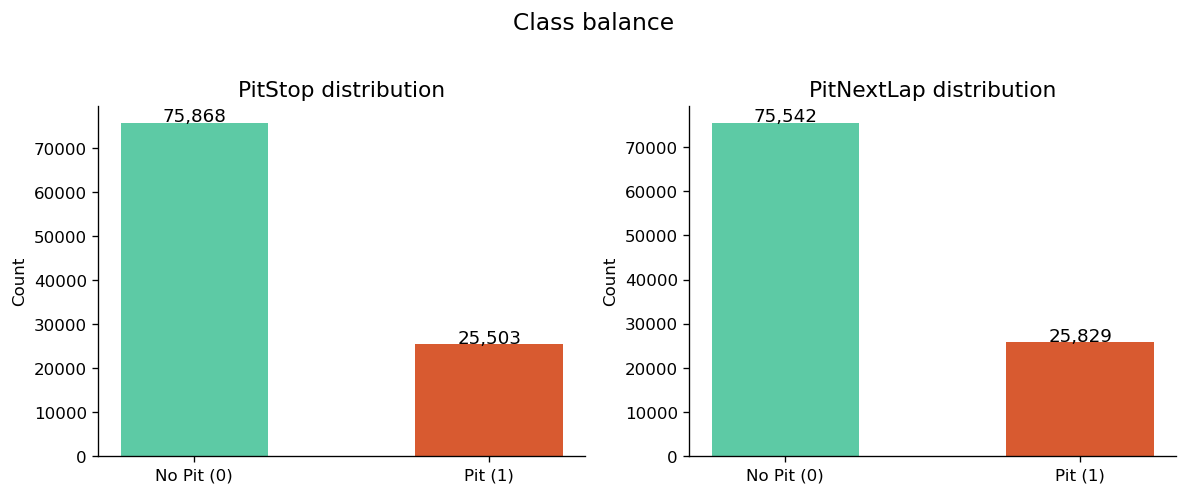

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, col in enumerate(['PitStop', 'PitNextLap']):
    counts = df_raw[col].value_counts()
    axes[i].bar(['No Pit (0)', 'Pit (1)'], counts.values,
                color=[cfg.COLORS['secondary'], cfg.COLORS['primary']],
                edgecolor='none', width=0.5)
    axes[i].set_title(f'{col} distribution', fontsize=13)
    axes[i].set_ylabel('Count')
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + 200, f'{v:,}', ha='center', fontsize=11)
plt.suptitle('Class balance', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '01_class_balance.png', bbox_inches='tight')
plt.show()

In [9]:
#Remove Preaseason Test
df = clean(df_raw)
print(f'After cleaning: {df.shape}')

[clean] Dropped 5,062 pre-season rows → 96,309 remain
[clean] Filled 66 nulls in Compound with 'UNKNOWN'
After cleaning: (96309, 16)


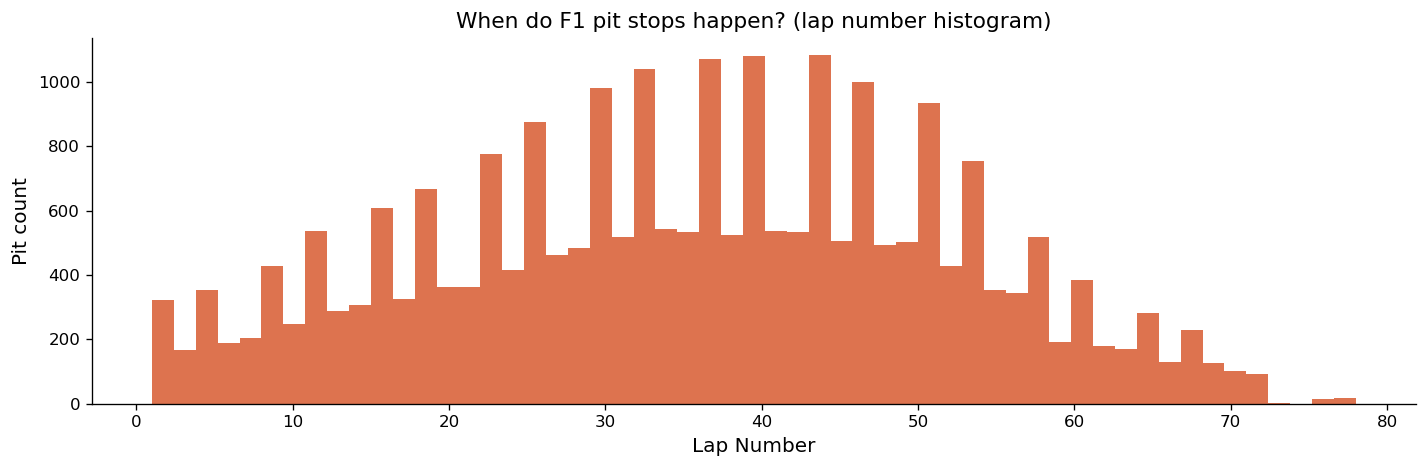

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
pit_laps = df[df['PitNextLap'] == 1]['LapNumber']
ax.hist(pit_laps, bins=55, color=cfg.COLORS['primary'], edgecolor='none', alpha=0.85)
ax.set_xlabel('Lap Number', fontsize=12)
ax.set_ylabel('Pit count', fontsize=12)
ax.set_title('When do F1 pit stops happen? (lap number histogram)', fontsize=13)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '02_pitstop_lap_dist.png', bbox_inches='tight')
plt.show()

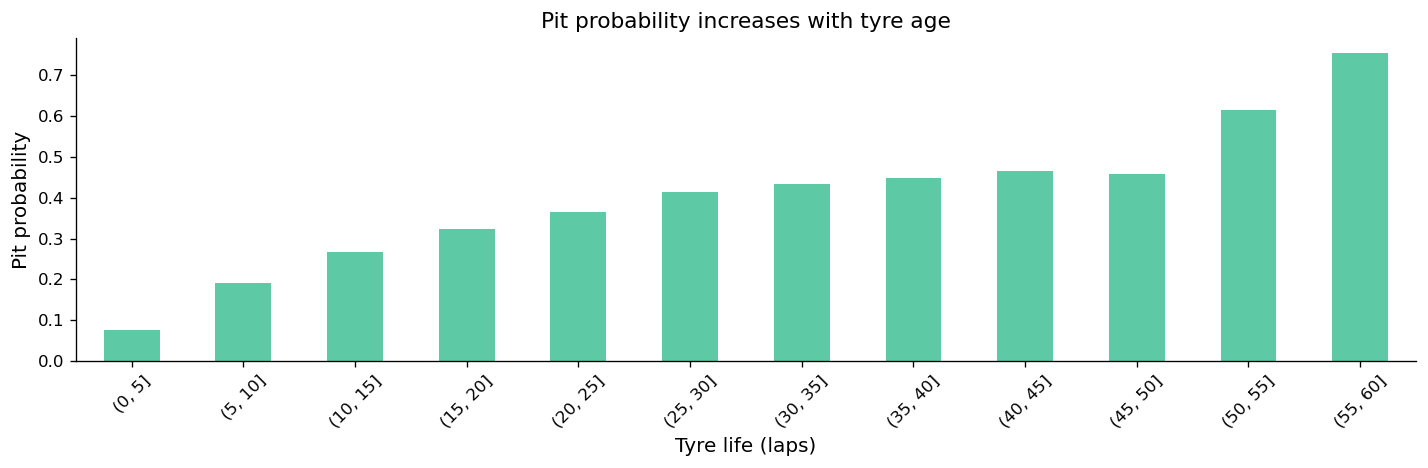

In [11]:
# Pit rate vs tyre life
tyre_bins = pd.cut(df['TyreLife'], bins=range(0, 65, 5))
pit_rate  = df.groupby(tyre_bins, observed=True)['PitNextLap'].mean()

fig, ax = plt.subplots(figsize=(12, 4))
pit_rate.plot(kind='bar', ax=ax, color=cfg.COLORS['secondary'], edgecolor='none')
ax.set_xlabel('Tyre life (laps)', fontsize=12)
ax.set_ylabel('Pit probability', fontsize=12)
ax.set_title('Pit probability increases with tyre age', fontsize=13)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '03_pit_rate_vs_tyre_life.png', bbox_inches='tight')
plt.show()

               PitRate   Laps
Compound                     
UNKNOWN       0.575758     66
HARD          0.321077  43052
SOFT          0.241107  11891
INTERMEDIATE  0.194744   5556
MEDIUM        0.191031  35345
WET           0.017544    399


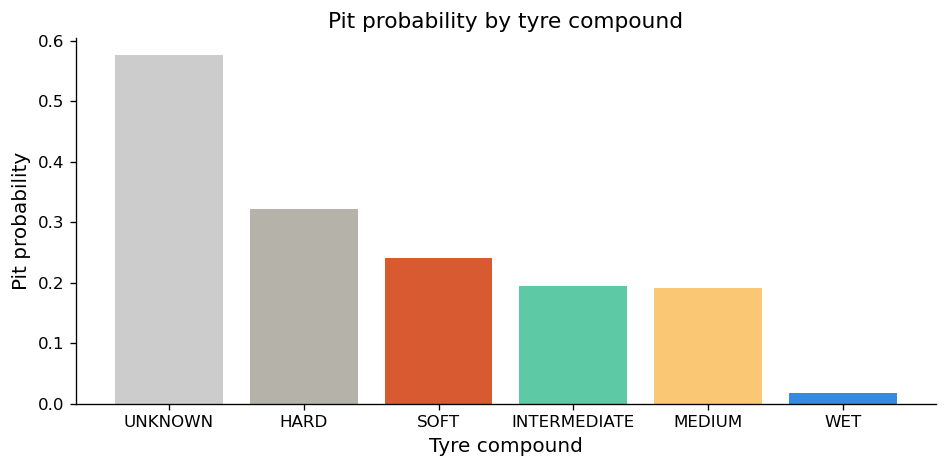

In [12]:
# Pit rate by tyre compound
pit_by_compound = (
    df.groupby('Compound', observed=True)['PitNextLap']
      .agg(['mean', 'count'])
      .rename(columns={'mean': 'PitRate', 'count': 'Laps'})
      .sort_values('PitRate', ascending=False)
)
print(pit_by_compound)

compound_colors = {
    'SOFT': cfg.COLORS['primary'], 'MEDIUM': cfg.COLORS['amber'],
    'HARD': cfg.COLORS['gray'],    'INTERMEDIATE': cfg.COLORS['secondary'],
    'WET':  cfg.COLORS['blue'],    
}
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pit_by_compound.index, pit_by_compound['PitRate'],
       color=[compound_colors.get(c, '#ccc') for c in pit_by_compound.index],
       edgecolor='none')
ax.set_xlabel('Tyre compound', fontsize=12)
ax.set_ylabel('Pit probability', fontsize=12)
ax.set_title('Pit probability by tyre compound', fontsize=13)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '04_pit_rate_by_compound.png', bbox_inches='tight')
plt.show()

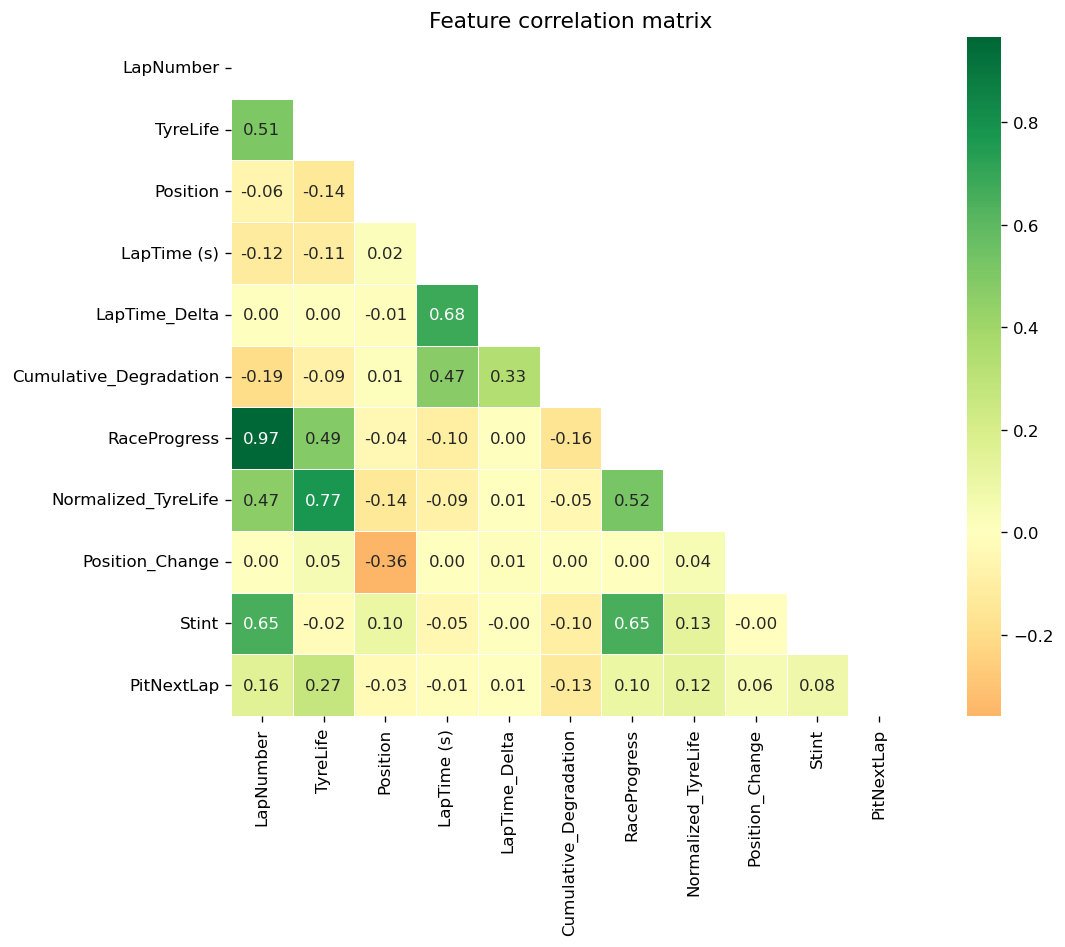

In [13]:
# Correlation heatmap of numeric features
num_cols = [
    'LapNumber', 'TyreLife', 'Position', 'LapTime (s)',
    'LapTime_Delta', 'Cumulative_Degradation',
    'RaceProgress', 'Normalized_TyreLife',
    'Position_Change', 'Stint', 'PitNextLap'
]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, ax=ax,
            linewidths=0.4, square=True)
ax.set_title('Feature correlation matrix', fontsize=13)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '06_correlation_heatmap.png', bbox_inches='tight')
plt.show()

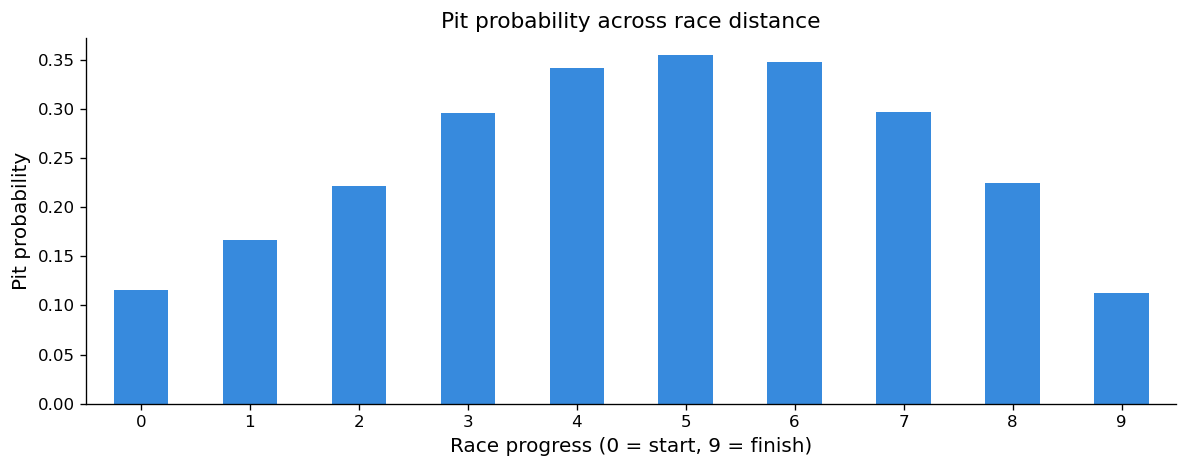

In [14]:
# Pit rate by race progress bucket
df['ProgressBucket'] = pd.cut(df['RaceProgress'],
                               bins=10, labels=False)
pit_by_prog = df.groupby('ProgressBucket')['PitNextLap'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
pit_by_prog.plot(kind='bar', ax=ax, color=cfg.COLORS['blue'], edgecolor='none')
ax.set_xlabel('Race progress (0 = start, 9 = finish)', fontsize=12)
ax.set_ylabel('Pit probability', fontsize=12)
ax.set_title('Pit probability across race distance', fontsize=13)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '07_pit_rate_vs_race_progress.png', bbox_inches='tight')
plt.show()

## 5. EDA Summary

| Finding | Detail |
|---|---|
| Dataset size | ~98k rows after removing pre-season |
| Target imbalance | ~74.5% no-pit vs 25.5% pit - needs handling |
| Pit windows | Cluster around laps 15–25 and 40–55 |
| Tyre age | Strong predictor - pit rate rises sharply after ~20 laps |
| Compound | SOFT pitted earliest, HARD latest |
| Lap time delta | Slight rightward shift before pits (slower laps) |
| Most correlated | `TyreLife`, `Normalized_TyreLife`, `RaceProgress` |

